# Testing

This notebook build the test cases for the algorithm.

In [1]:
load("tcases.sage")

NumPy version: 1.26.2
Pandas version: 2.2.1
Matplotlib version: 3.8.0
Last Updated: 08/04/2024 19:05:29


# Testing partition module

In [2]:
np.random.seed(27456) # To ensure reproductibility

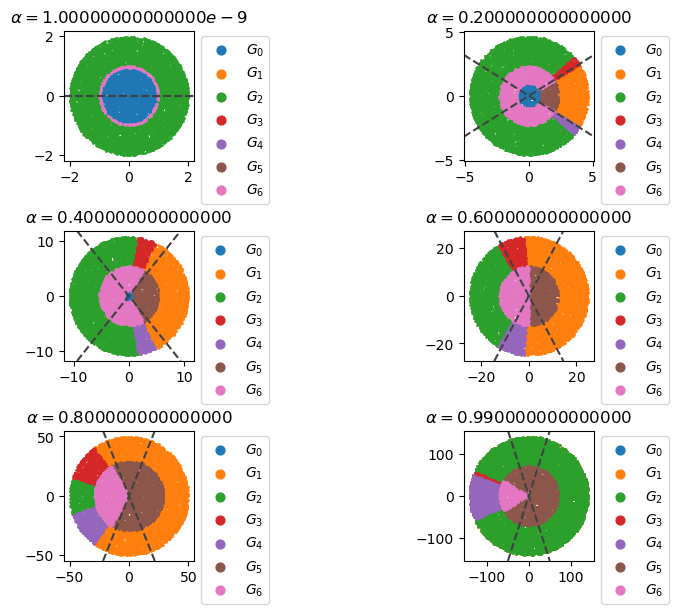

In [3]:
fig, ax = plt.subplots(3,2,figsize=(8,6),constrained_layout=True)
plot_partition(ax = ax[0,0], α = 1.0e-09)
plot_partition(ax = ax[0,1], α = 2.0e-01)
plot_partition(ax = ax[1,0], α = 4.0e-01)
plot_partition(ax = ax[1,1], α = 6.0e-01)
plot_partition(ax = ax[2,0], α = 8.0e-01, rmax = 50)
plot_partition(ax = ax[2,1], α = 9.9e-01, rmax = 150)
plt.show()

In [4]:
# Save test cases
def create_partition_tcases(eps = 1.0e-15):
    count = 1
    for r0 in [0.90, 0.95]:
        for alpha in [1e-9, 0.2, 0.4, 0.6, 0.8, 0.99]:
            partition_tcase = create_partition(α = alpha, ε = eps, r0 = r0)
            with open(f"partition/tt_partition_c{count:04d}.txt", 'w') as fp:
                fp.write("# r0 alpha re_z im_z region\n")
                for index, row in partition_tcase.iterrows():
                    fp.write(f"{fmt(r0)} {fmt(row['alpha'])} {fmt(row['re_z'])} {fmt(row['im_z'])} {row['region']:01d}\n")
            count += 1

create_partition_tcases()

# Testing `algorithm` module

For testing each algorithm function in an isolated way, we use the following special cases:
\begin{equation}
E_{1/2, 1}(z) = e^{z^2}\mathrm{erfc}(-z),
\end{equation}
and
\begin{equation}
E_{1/2, 3/2}(z) = \frac{1}{z}\big(e^{z^2}\mathrm{erfc}(-z) - 1\big),
\end{equation}

In [5]:
z = [
    (-7.33057219e-02-5.11934762e-01j, -2.71670473e-01-3.61159944e-01j, 
     +2.65104392e-01+4.93166724e-01j, +3.83251931e-01-7.20912195e-01j,
     +6.15420692e-01+4.94737446e-01j, +5.77022431e-01+7.31978260e-01j, 
     +5.50863360e-01+3.20026771e-01j, +3.19070375e-01-6.61764960e-01j, 
     -4.45577540e-01-6.89742478e-01j, +1.59189786e-01+3.86077993e-02j),
    (+1.00809273e+01+2.22251668e+00j, +4.22589759e+00+9.54335685e+00j,
     +7.07970270e+00-4.66671354e+00j, +1.03652185e+01+2.66482346e+00j,
     +7.36990152e+00+5.61334844e+00j, +1.02336488e+01-1.44223606e+00j,
     +8.17467292e+00-2.42910054e+00j, +4.34347484e+00+6.98890345e+00j,
     +9.93249059e+00+3.48082382e+00j, +5.72222055e+00+5.86522403e+00j),
    (-8.81638303e+00+4.53794350e+00j, -9.83286816e+00+3.89528981e+00j,
     -8.15754405e+00+3.51012135e+00j, -9.75448297e+00+4.41974518e+00j,
     -1.01655301e+01-1.84058210e+00j, -7.74353934e+00-7.18631674e+00j,
     -8.35629806e+00+6.52829764e+00j, -5.54981503e+00+6.60796993e+00j,
     -3.88573272e+00-7.26142380e+00j, -7.05943454e+00+7.46849452e+00j),
    (-3.22342758e-01+8.45119872e+00j, +7.13347688e-01+1.06864127e+01j,
     +4.77462676e-01+1.00665352e+01j, +9.88018957e-01+1.05615109e+01j,
     -9.62473717e-01+9.61880150e+00j, +1.39209663e+00+8.13417968e+00j,
     -1.11915976e-01+9.18185740e+00j, +1.93827983e+00+1.05413022e+01j,
     -9.93493529e-01+1.02465564e+01j, +1.13040766e+00+9.12078090e+00j),
    (-3.75588680e-01-9.83203507e+00j, -8.88774219e-01-9.55277101e+00j,
     -6.41990869e-02-8.27306571e+00j, -7.41899625e-02-8.24863509e+00j,
     +7.94012305e-01-9.21742744e+00j, +2.04734829e+00-1.04412313e+01j,
     +1.24541783e+00-9.61437859e+00j, +1.57560906e+00-9.41839253e+00j,
     +8.01100940e-01-9.12867016e+00j, -1.52222011e+00-9.69011955e+00j),
    (+4.08373780e+00+2.53485316e+00j, +4.28734692e+00+1.48338558e+00j,
     +5.58693005e+00-5.46478678e+00j, +4.20513707e+00-1.51605969e-01j,
     +1.06269938e+00-3.29532657e+00j, +5.31116784e+00-5.90116020e+00j,
     +6.98695414e+00+4.17832152e+00j, +6.38791794e+00-2.61371742e+00j,
     +4.76970575e+00-3.58214698e+00j, +2.03837467e+00-3.27614785e+00j),
    (-5.00775165e+00+4.08876443e+00j, +1.29206756e+00+6.06330787e+00j,
     -3.61542114e+00-6.31484347e+00j, -4.41578509e+00+6.29748333e+00j,
     -1.98160394e+00+2.44111893e+00j, -8.53012232e-02+7.19321871e+00j,
     -7.28144099e+00-2.17268099e+00j, -6.56039361e+00+4.33423743e+00j,
     -3.85833401e+00-4.25315083e+00j, -2.97631495e+00+6.48320798e+00j)
]

In [12]:
count = 1
def create_partition_tcases_1():
    global count
    def expected(x):
        return complex(exp(x^2) * erfc(-x))
    r0, alpha, beta = 0.95, 0.5, 1.0
    with open(f"algorithm/tt_algorithm_c{count:04d}.txt", 'w') as fp:
        fp.write("# r0 alpha beta z expected region\n")
        for region in range(7):
            for x in z[region]:
                fp.write(f"{fmt(float(r0))} {fmt(float(alpha))} {fmt(float(beta))} {fmt(complex(x))} {fmt(expected(x))} {region}\n")
        count += 1

def create_partition_tcases_2():
    global count
    def expected(x):
        return complex((1/x) * (exp(x * x) * erfc(-x) - 1))
    r0, alpha, beta = 0.95, 0.5, 1.5
    with open(f"algorithm/tt_algorithm_c{count:04d}.txt", 'w') as fp:
        fp.write("# r0 alpha beta z expected region\n")
        for region in range(7):
            for x in z[region]:
                #print(expected(x))
                fp.write(f"{fmt(float(r0))} {fmt(float(alpha))} {fmt(float(beta))} {fmt(complex(x))} {fmt(expected(x))} {region}\n")
        count += 1

create_partition_tcases_1()
create_partition_tcases_2()

In [ ]:

@pytest.mark.parametrize("z", )
def test_mittleff1(z):
    α, β, z = arb("0.5"), arb("1.0"), acb(z)
    computed = mittleff1(α, β, z)
    assert(isclose(expected(z), computed))

@pytest.mark.parametrize("z", )
def test_mittleff2(z):
    α, β, z = arb("0.5"), arb("1.0"), acb(z)
    computed = mittleff2(α, β, z)
    assert(isclose(expected(z), computed))

@pytest.mark.parametrize("z", )
def test_mittleff3(z):
    α, β, z = arb("0.5"), arb("1.0"), acb(z)
    computed = mittleff3(α, β, z)
    assert(isclose(expected(z), computed))

@pytest.mark.parametrize("z", [
    
    ])
def test_mittleff4(z):
    α, β, z = arb("0.5"), arb("1.0"), acb(z)
    computed = mittleff4(α, β, z)
    assert(isclose(expected(z), computed))

@pytest.mark.parametrize("z", [
    
    ])
def test_mittleff5(z):
    α, β, z = arb("0.5"), arb("1.0"), acb(z)
    computed = mittleff5(α, β, z)
    assert(isclose(expected(z), computed))

@pytest.mark.parametrize("z", [
    -5.00775165e+00+4.08876443e+00j,
    +1.29206756e+00+6.06330787e+00j,
    -3.61542114e+00-6.31484347e+00j,
    -4.41578509e+00+6.29748333e+00j,
    -1.98160394e+00+2.44111893e+00j,
    -8.53012232e-02+7.19321871e+00j,
    -7.28144099e+00-2.17268099e+00j,
    -6.56039361e+00+4.33423743e+00j,
    -3.85833401e+00-4.25315083e+00j,
    -2.97631495e+00+6.48320798e+00j,
    ])
def test_mittleff6(z):
    α, β, z = arb("0.5"), arb("1.0"), acb(z)
    computed = mittleff6(α, β, z)
    assert(isclose(expected(z), computed))

@pytest.mark.parametrize("z", [
    
    ])
def test_mittleff6_beta_large(z):
    α, β, z, ε = arb("0.5"), arb("1.5"), acb(z), arb("1e-15")
    computed = mittleff6(α, β, z)
    assert(isclose(expected_beta_large(z), computed))    

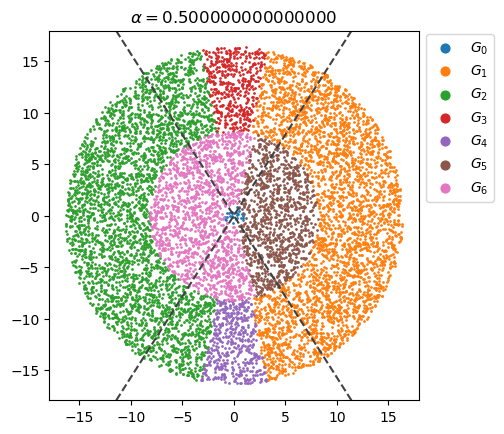

In [6]:
fig, ax = plt.subplots()
plot_partition(ax, α = 0.5)
plt.show()

In [9]:
# Save test cases
def create_algorithm_tcases(eps = 1.0e-15):
    count = 1
    for r0 in [0.95]:
        for alpha, beta in [(0.5, 1.0), (0.5, 1.5)]:
            algorithm_tcase = create_partition(α = alpha, ε = eps, r0 = r0)
            algorithm_tcase['beta'] = beta
            algorithm_tcase['expected_re'] = algorithm_tcase.apply(lambda r: expected1(r['re_z']+1j*r['im_z']).real, axis=1)
            algorithm_tcase['expected_im'] = algorithm_tcase.apply(lambda r: expected1(r['re_z']+1j*r['im_z']).imag, axis=1)
            #algorithm_tcase[['alpha', 'beta', 're_z', 'im_z', 'expected_re', 'expected_im', 'region']].head()
            with open(f"algorithm/tt_algorithm_c{count:04d}.txt", 'w') as fp:
                fp.write("# r0 alpha beta re_z im_z expected_re expected_im region\n")
                for index, row in algorithm_tcase.iterrows():
                    fp.write(f"{fmt(r0)} {fmt(row['alpha'])} {fmt(row['beta'])} {fmt(row['re_z'])} {fmt(row['im_z'])} {fmt(row['expected_re'])} {fmt(row['expected_im'])} {row['region']:01d}\n")
            count += 1

create_algorithm_tcases()

In [22]:
# import flint
# from flint import acb, arb

# def MittagLefflerSeries(α: arb, β: arb, z: acb):
#     acc = arb(float(1e-15))
#     # Function defining the series term
#     fn = lambda k: z^k/gamma(α * k + β)
#     k, s = 0, acb.rgamma(acb(β))
#     while True:
#         term = z**k * acb.rgamma(acb(α * arb(int(k)) + β))
#         print(s)
#         if abs(term) < acc:
#             break
#         s += term
#         k += 1
#     return s

In [23]:
def nsum_numeric_series(α, β, z, tol = 1e-15):
    ps = []
    func = lambda k: z^k/gamma(α * k + β)
    s = 0
    n = 0
    while True:
        term = func(n)
        ps.append([n, abs(term)])
        if abs(term) < tol:
            #print(n)
            break
        s += term
        n += 1
    return s, ps

In [24]:
s, ps = nsum_numeric_series(a, b, z_j)
s

3.87659753526743e21

In [25]:
len(ps)

317

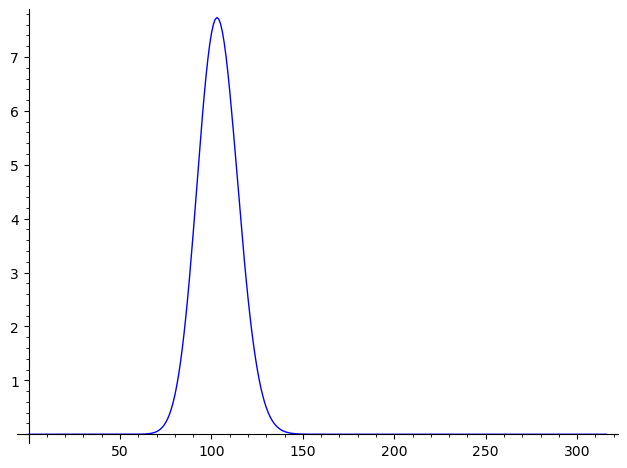

In [19]:
list_plot(ps, plotjoined = True)

In [3]:
test_case_001 = MittagLefflerCompareTable(
    pd.DataFrame({
        "α": 1.0,
        "β": 1.0,
        "z": sample_from_disk(r = 1.0, n = 2),
    }))

In [4]:
test_case_001[]

,α,β,z,Res,Res (Seybold),Res (Garrapa),Err (Seybold),Err (Garrapa)
0,1.00000000000000,1.00000000000000,-0.653177-0.169949j,0.512893-0.088015j,0.512893-0.088015j,0.512893-0.088015j,7.82419739633706e-17,1.6381488369243532e-16
1,1.00000000000000,1.00000000000000,0.102325+0.165823j,1.092548+0.182849j,1.092548+0.182849j,1.092548+0.182849j,1.8499119764813223e-16,2.3076659820710466e-16


In [67]:
def my_format(n):
    s = f"{n:.15E}"
    c, p = s.split("E")
    return f"{c}E{p.zfill(4)}"

In [68]:
my_format(0.345)

'3.450000000000000E-001'

In [54]:
def to_csv(df: pd.DataFrame, fname = "test.out"):
    with open(fname, "w") as fp:
        alpha, beta = list(df[["α", "β"]].iloc[int(0)])
        fp.write(f"# {alpha:+.15E} {beta:+.15E}\n")
        fp.write(f"# Column names here")
        for _, row in df.iterrows():
            alpha, beta, z, r1, r2, r3, err2, err3 = row
            fp.write(f"{z:+.15E}, {r1:+.15E}, {r2:+.15E}, {r3:+.15E}, {err2:+.15E}, {err3:+.15E}")
            fp.write("\n")

In [55]:
to_csv(test_case_001)

In [56]:
!cat test.out

# +1.000000000000000E+0, +1.000000000000000E+0
# Column names here-6.531768526345925E-01-1.699490382220224E-01j, +5.128928895002611E-01-8.801465564504228E-02j, +5.128928895002612E-01-8.801465564504232E-02j, +5.128928895002610E-01-8.801465564504250E-02j, +7.824197396337060E-17, +1.638148836924353E-16
+1.023250222814859E-01+1.658232979634878E-01j, +1.092548307645230E+00+1.828489992101338E-01j, +1.092548307645230E+00+1.828489992101334E-01j, +1.092548307645230E+00+1.828489992101336E-01j, +1.849911976481322E-16, +2.307665982071047E-16


### Tests for $E_{1, 1}(z) = \mathrm{exp}(z)$

In [7]:
printfmt("# α, β, z, expected_analytic", True)
for α, β, z in [(1, 1, CDF(i)) for i in sample_from_disk()]:
    expected = exp(z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected))}"
    printfmt(line)

# α, β, z, expected_analytic
(+1.00000000000000e+00, +1.00000000000000e+00, -3.40475719667089e+00-8.85878317058847e-01j, +2.10120515091511e-02-2.57239615219903e-02j),
(+1.00000000000000e+00, +1.00000000000000e+00, +2.52852209883197e+00+4.09760842512654e+00j, -7.22990913669645e+00-1.02398150139671e+01j),
(+1.00000000000000e+00, +1.00000000000000e+00, -3.90480340771361e+00+1.12055741529628e+00j, +8.76667693588739e-03+1.81373358894973e-02j),
(+1.00000000000000e+00, +1.00000000000000e+00, +4.06038416915036e+00+9.87442768167358e-01j, +3.19460268292296e+01+4.84051186157719e+01j),
(+1.00000000000000e+00, +1.00000000000000e+00, -2.22432343967780e+00+3.11052129457214e+00j, -1.08088360666470e-01+3.35953346022400e-03j),
(+1.00000000000000e+00, +1.00000000000000e+00, +1.20262716907508e+00-3.04007078491374e+00j, -3.31171091116626e+00-3.37370936602483e-01j),
(+1.00000000000000e+00, +1.00000000000000e+00, -6.77979186133673e-01-7.71287909629331e-01j, +3.63986035871192e-01-3.53856424317418e-01j),
(+1.0

### Tests for $E_{2, 1}(z) = \mathrm{cosh}(\sqrt{z})$

In [8]:
printfmt("# α, β, z, expected_analytic", True)
for α, β, z in [(2, 1, CDF(i)) for i in sample_from_disk()]:
    expected = cosh(sqrt(z))
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected))}"
    printfmt(line)

# α, β, z, expected_analytic
(+2.00000000000000e+00, +1.00000000000000e+00, -4.45831982466673e+00-1.87270847320298e-01j, -5.15621936359384e-01-3.80139607318037e-02j),
(+2.00000000000000e+00, +1.00000000000000e+00, +4.14341351912973e+00-2.20547084670264e+00j, +3.59415163800734e+00-2.01867537883378e+00j),
(+2.00000000000000e+00, +1.00000000000000e+00, +8.37277882968266e-01-1.66307595885308e+00j, +1.32369028093052e+00-9.45755818018069e-01j),
(+2.00000000000000e+00, +1.00000000000000e+00, +1.06992639285024e+00+1.13698947655198e+00j, +1.52458665189399e+00+6.73231100428430e-01j),
(+2.00000000000000e+00, +1.00000000000000e+00, +3.57792709173288e+00+3.32311253947560e-01j, +3.38373575305228e+00+2.84485358649774e-01j),
(+2.00000000000000e+00, +1.00000000000000e+00, +9.56902492076838e-01-1.03786394823724e+00j, +1.46854626478549e+00-6.04082989042428e-01j),
(+2.00000000000000e+00, +1.00000000000000e+00, +7.30941499075079e-01-3.69239995833102e+00j, +7.82379315755719e-01-2.00602624951081e+00j),
(+2.0

### Tests for $E_{2, 2}(z) = \frac{\mathrm{sinh}\sqrt{z}}{\sqrt{z}}$

In [9]:
printfmt("# α, β, z, expected_analytic", True)
for α, β, z in [(2, 2, CDF(i)) for i in sample_from_disk()]:
    expected = sinh(sqrt(z))/sqrt(z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected))}"
    printfmt(line)

# α, β, z, expected_analytic
(+2.00000000000000e+00, +2.00000000000000e+00, +1.42816090040699e+00+7.24011186922847e-01j, +1.25078228495404e+00+1.38723101957171e-01j),
(+2.00000000000000e+00, +2.00000000000000e+00, -1.27627031566472e+00-9.13483760278772e-01j, +7.94116830973412e-01-1.33540662211768e-01j),
(+2.00000000000000e+00, +2.00000000000000e+00, +2.35759544334568e+00-1.11711968245461e-01j, +1.44181569101927e+00-2.33940476945834e-02j),
(+2.00000000000000e+00, +2.00000000000000e+00, -9.50393652654187e-01-3.14039403651523e+00j, +7.72466472598170e-01-4.69494429384765e-01j),
(+2.00000000000000e+00, +2.00000000000000e+00, -9.16987572915578e-01+6.78296068357670e-01j, +8.50436230881818e-01+1.02957826043312e-01j),
(+2.00000000000000e+00, +2.00000000000000e+00, -2.17475898073821e-01+3.59727723691290e+00j, +8.58431036412957e-01+5.77498231504739e-01j),
(+2.00000000000000e+00, +2.00000000000000e+00, +1.46491630722602e+00+2.42366410440866e+00j, +1.20848760125371e+00+4.63239477256404e-01j),
(+2.0

### Tests for $E_{1/2, 1}(z) = e^{z^2}\mathrm{erfc}(-z)$

In [10]:
printfmt("# α, β, z, expected_analytic", True)
for α, β, z in [(0.5, 1.0, CDF(i)) for i in sample_from_disk()]:
    expected = exp(z**2) * erfc(-z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected))}"
    printfmt(line)

# α, β, z, expected_analytic
(+5.00000000000000e-01, +1.00000000000000e+00, +3.05599061557941e+00-3.87695953184331e-01j, -1.40246882254414e+04-1.36537376534274e+04j),
(+5.00000000000000e-01, +1.00000000000000e+00, -9.23710183826855e-01+3.13759413949194e+00j, +5.61986352262727e-02+1.70667811509730e-01j),
(+5.00000000000000e-01, +1.00000000000000e+00, -4.79154610412735e-01+4.79724812930007e+00j, +1.24628403325567e-02+1.19009252388690e-01j),
(+5.00000000000000e-01, +1.00000000000000e+00, -1.59609335170830e+00-2.85441065775479e+00j, +9.26853988257281e-02-1.49757972156775e-01j),
(+5.00000000000000e-01, +1.00000000000000e+00, -1.08788609049404e+00-2.70399388838925e+00j, +8.45644694983115e-02-1.82856833837033e-01j),
(+5.00000000000000e-01, +1.00000000000000e+00, -1.26064394297582e+00+1.74294242077950e+00j, +1.76633675106206e-01+1.96209807034830e-01j),
(+5.00000000000000e-01, +1.00000000000000e+00, +1.63053954981789e-01-3.80306103440080e+00j, -7.15852374334638e-03-1.53787502851654e-01j),
(+5.0

### Tests for SIAM table

In [11]:
printfmt("# α, β, z, expected_seybold, expected_garrapa", True)
for α, β, z in [
    (0.6,  0.8, 7.0), # => 4.24680224e+11
    (0.6,  0.8, 20.0), # => 4.50513132e+64
    (0.6,  0.8, -7.0), # => 0.036402965145
    (0.6,  0.8, -50.0), # => 0.004463867842
    (0.6,  0.8, 7.0*exp(0.6 * pi * I)),
    (0.6,  0.8, 20.0*exp(0.6 * pi * I)),
    (0.6, 1.25, 7.0),
    (0.6, 1.25, 20.0),
    (0.6, 1.25, -7.0),
    (0.6, 1.25, -50.0),
    (0.6, 1.25, 7.0*exp(0.6 * pi * I)),
    (0.6, 1.25, 20.0*exp(0.6 * pi * I)),
    (0.6, -0.8, 7.0),
    (0.6, -0.8, 20.0),
    (0.6, -0.8, -7.0),
    (0.6, -0.8, -50.0),
    (0.6, -0.8, 7.0*exp(0.6 * pi * I)),
    (0.6, -0.8, 20.0*exp(0.6 * pi * I)),
]:
    expected_seybold, expected_garrapa = MittagLefflerSeybold(α, β, z), MittagLefflerGarrapa(α, β, z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected_seybold))}, {fmt(complex(expected_garrapa))}"
    printfmt(line)

# α, β, z, expected_seybold, expected_garrapa
(+6.00000000000000e-01, +8.00000000000000e-01, +7.00000000000000e+00+0.00000000000000e+00j, +4.24680224735076e+11+0.00000000000000e+00j, +4.24680224735076e+11+0.00000000000000e+00j),
(+6.00000000000000e-01, +8.00000000000000e-01, +2.00000000000000e+01+0.00000000000000e+00j, +4.50513132816147e+64+0.00000000000000e+00j, +4.50513132816147e+64+0.00000000000000e+00j),
(+6.00000000000000e-01, +8.00000000000000e-01, -7.00000000000000e+00+0.00000000000000e+00j, +3.64029651451777e-02+0.00000000000000e+00j, +3.64029651451777e-02+0.00000000000000e+00j),
(+6.00000000000000e-01, +8.00000000000000e-01, -5.00000000000000e+01+0.00000000000000e+00j, +4.46386784209422e-03+0.00000000000000e+00j, +4.46386784209422e-03+0.00000000000000e+00j),
(+6.00000000000000e-01, +8.00000000000000e-01, -2.16311896062463e+00+6.65739561406608e+00j, +5.09750817997945e-03+3.29981075238373e-02j, +5.09750817997950e-03+3.29981075238373e-02j),
(+6.00000000000000e-01, +8.000000000000

### Tests from https://github.com/JuliaMath/MittagLeffler.jl

#### testset `mittleff`

In [12]:
printfmt("# α, β, z, expected_julia, expected_seybold, expected_garrapa", True)
for α, β, z, expected_julia in [
    (0.5, 0.5, 0.5,  1.5403698281390346),
    (1.5, 0.5, 0.5, 1.1448466286155243),
    (2.3, 1, 0.7 + 2.0j, 1.201890136368392 + 0.7895394560075035j),
    (2.3, 1, 0.7 + 0.2j, 1.268233154873853 + 0.07914994421659409j),
]:
    expected_seybold, expected_garrapa = MittagLefflerSeybold(α, β, z), MittagLefflerGarrapa(α, β, z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected_julia))}, {fmt(complex(expected_seybold))}, {fmt(complex(expected_garrapa))}"
    printfmt(line)

# α, β, z, expected_julia, expected_seybold, expected_garrapa
(+5.00000000000000e-01, +5.00000000000000e-01, +5.00000000000000e-01+0.00000000000000e+00j, +1.54036982813903e+00+0.00000000000000e+00j, +1.54036982813903e+00+0.00000000000000e+00j, +1.54036982813903e+00+0.00000000000000e+00j),
(+1.50000000000000e+00, +5.00000000000000e-01, +5.00000000000000e-01+0.00000000000000e+00j, +1.14484662861552e+00+0.00000000000000e+00j, +1.14484662861552e+00+0.00000000000000e+00j, +1.14484662861552e+00+0.00000000000000e+00j),
(+2.30000000000000e+00, +1.00000000000000e+00, +7.00000000000000e-01+2.00000000000000e+00j, +1.20189013636839e+00+7.89539456007504e-01j, +1.20189013636839e+00+7.89539456007503e-01j, +1.20189013636839e+00+7.89539456007502e-01j),
(+2.30000000000000e+00, +1.00000000000000e+00, +7.00000000000000e-01+2.00000000000000e-01j, +1.26823315487385e+00+7.91499442165941e-02j, +1.26823315487385e+00+7.91499442165938e-02j, +1.26823315487385e+00+7.91499442165934e-02j),


#### testset `branches`

In [13]:
printfmt("# α, β, z, expected_julia, expected_seybold, expected_garrapa", True)
for α, β, z, expected_julia in [
    (0.9, 0.5, 22 + 22j, -2.7808021618204008e13-2.8561425165239754e13j),
    (0.1, 1.05, 0.9 + 0.5j, 0.17617901349590603+2.063981943021305j),
    (4.1, 1, 1, 1.0358176744122032),
]:
    expected_seybold, expected_garrapa = MittagLefflerSeybold(α, β, z), MittagLefflerGarrapa(α, β, z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected_julia))}, {fmt(complex(expected_seybold))}, {fmt(complex(expected_garrapa))}"
    printfmt(line)

# α, β, z, expected_julia, expected_seybold, expected_garrapa
(+9.00000000000000e-01, +5.00000000000000e-01, +2.20000000000000e+01+2.20000000000000e+01j, -2.78080216182040e+13-2.85614251652398e+13j, -2.78080216182040e+13-2.85614251652389e+13j, -2.78080216182040e+13-2.85614251652394e+13j),
(+1.00000000000000e-01, +1.05000000000000e+00, +9.00000000000000e-01+5.00000000000000e-01j, +1.76179013495906e-01+2.06398194302131e+00j, +1.76179013495906e-01+2.06398194302131e+00j, +1.76179013495905e-01+2.06398194302131e+00j),
(+4.10000000000000e+00, +1.00000000000000e+00, +1.00000000000000e+00+0.00000000000000e+00j, +1.03581767441220e+00+0.00000000000000e+00j, +1.03581767441320e+00-1.58603289232165e-17j, +1.03581767441320e+00+0.00000000000000e+00j),


#### testset [issue #8](https://github.com/JuliaMath/MittagLeffler.jl/issues/8)

In [14]:
printfmt("# α, β, z, expected_julia, expected_seybold, expected_garrapa", True)
for α, β, z, expected_julia in [
    (0.5, 1, -12, 0.046854221014893775),
]:
    expected_seybold, expected_garrapa = MittagLefflerSeybold(α, β, z), MittagLefflerGarrapa(α, β, z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected_julia))}, {fmt(complex(expected_seybold))}, {fmt(complex(expected_garrapa))}"
    printfmt(line)

# α, β, z, expected_julia, expected_seybold, expected_garrapa
(+5.00000000000000e-01, +1.00000000000000e+00, -1.20000000000000e+01+0.00000000000000e+00j, +4.68542210148938e-02+0.00000000000000e+00j, +4.68542210148938e-02+0.00000000000000e+00j, +4.68542210148938e-02+0.00000000000000e+00j),


#### testset [issue #12](https://github.com/JuliaMath/MittagLeffler.jl/issues/12)

In [15]:
printfmt("# α, β, z, expected_julia, expected_seybold, expected_garrapa", True)
for α, β, z, expected_julia in [
    (0.125, 1, -1, -0.481952081535048487353320281623),
]:
    expected_seybold, expected_garrapa = MittagLefflerSeybold(α, β, z), MittagLefflerGarrapa(α, β, z)
    line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected_julia))}, {fmt(complex(expected_seybold))}, {fmt(complex(expected_garrapa))}"
    printfmt(line)

# α, β, z, expected_julia, expected_seybold, expected_garrapa
(+1.25000000000000e-01, +1.00000000000000e+00, -1.00000000000000e+00+0.00000000000000e+00j, -4.81952081535048e-01+0.00000000000000e+00j, +4.81952081535048e-01+0.00000000000000e+00j, +4.81952081535049e-01+0.00000000000000e+00j),


### Tests from https://github.com/lrtfm/Mittag-Leffler-Function

In [16]:
# TODO
# printfmt("# α, β, z, expected_mathematica, expected_seybold, expected_garrapa")
# for α, β, z, expected_mathematica in [
#     ( 34.77,  64.34,  51.44, -0.12286 * 10^(-87)),
#     (   15., -14.02,  88.43, 0.18381 * 10^(10)),
#     ( 58.61,  77.55,   58.8, -0.48719 * 10^(-112)),
#     ( 26.21, -21.76,  15.48, -0.11615 * 10^(21)),
#     ( 4.445,  53.82,  19.99, -0.47868 * 10^(-69)),
#     ( 75.49, -20.64,   40.7, 0.48908 * 10^(19)),
#     ( 24.28,   61.7,  74.87, -0.67739 * 10^(-83)),
#     ( 44.24,  51.02,  82.56, -0.30398 * 10^(-64)),
#     ( 68.78, -24.52,    79., 0.10458 * 10^(25)),
#     ( 35.92,  -56.8,  31.85, 0.33730 * 10^(76)),
#     ( 73.63,  58.08,  53.41, -0.17842 * 10^(-76)),
#     ( 39.47,  89.86, 8.9949, -0.11363 * 10^(-135)),
#     ( 68.34, -34.49,  11.17, 0.53437 * 10^(39)),
#     (  70.4,  34.25,  13.63, -0.47823 * 10^(-37)),
#     ( 44.23, -12.27,  67.87, 0.22686 * 10^(9)),
#     ( 1.958,   66.7,  49.52, -0.65523 * 10^(-92)),
#     ( 33.09,  53.77,  18.97, -0.58396 * 10^(-69)),
#     ( 42.43, -66.55,   49.5, 0.17253 * 10^(94)),
#     ( 27.03,   72.4,  14.76, -0.21287 * 10^(-102)),
#     ( 19.71,  97.97,  5.497, -0.11926 * 10^(-151)),
# ]:
#     expected_seybold, expected_garrapa = MittagLefflerSeybold(α, β, z), MittagLefflerGarrapa(α, β, z)
#     line = f"{fmt(float(α))}, {fmt(float(β))}, {fmt(complex(z))}, {fmt(complex(expected_mathematica))}, {fmt(complex(expected_seybold))}, {fmt(complex(expected_garrapa))}"
#     printfmt(line, fp)

### Closing file

In [17]:
if save_file and not (fp is None):
    fp.close()
    fp = None